In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

from sir_graph.dynamics import simulate, run_ensemble
from sir_graph.emm import (
    search_model_b_subgroups,
    search_subgroups,
)
from sir_graph.geometric import random_geometric
from sir_graph.havel_hakimi import (
    havel_hakimi,
    randomize_degree_preserving,
)
from sir_graph.parameters import NodeParams
from sir_graph.analysis import (
    aggregate_cascade_by_person,
    cascade_observations,
    descendant_counts,
    fit_degree_baseline,
    opportunity_contact_steps,
    weighted_opportunity_contact_steps,
    model_b_observations,
    per_node_spreading_metrics,
)

In [4]:
N_NODES = 1000
DATA_SEED = 22

people = pd.read_csv("../data/synthetic_data.csv")

people = (
    people
    .sample(n=N_NODES, random_state=DATA_SEED)
    .reset_index(drop=True)
)

people.insert(
    0,
    "node_id",
    np.arange(N_NODES, dtype=np.int64)
)

infection_rate = people[
    "infection_rate"
].to_numpy(dtype=np.float64)

people.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate
0,0,35220,62,Female,Student,0,0,0,0.3329
1,1,29487,71,Female,Office-based,0,0,0,0.3428
2,2,38566,40,Male,Agriculture,1,1,1,0.3998
3,3,20529,70,Male,Office-based,1,1,0,0.4563
4,4,30182,54,Male,Healthcare,0,0,0,0.3793


In [5]:


N_NODES = 1000
RADIUS = 0.0723
NETWORK_SEED = 22

baseline_graph, positions = random_geometric(
    N_NODES,
    RADIUS,
    rng=NETWORK_SEED,
)

print("Nodes:", baseline_graph.n_nodes)
print("Edges:", baseline_graph.n_edges)
print("Mean degree:", baseline_graph.degree().mean())

Nodes: 1000
Edges: 7723
Mean degree: 15.446


In [6]:
original_degree_sequence = baseline_graph.degree().copy()

print("Mean degree:", original_degree_sequence.mean())
print("Min degree:", original_degree_sequence.min())
print("Max degree:", original_degree_sequence.max())

Mean degree: 15.446
Min degree: 2
Max degree: 27


In [7]:


hh_graph = havel_hakimi(original_degree_sequence)

In [8]:

print("HH nodes:", hh_graph.n_nodes)
print("HH edges:", hh_graph.n_edges)
print("HH mean degree:", hh_graph.degree().mean())

print(
    "Degrees identical:",
    np.array_equal(
        hh_graph.degree(),
        original_degree_sequence
    )
)

HH nodes: 1000
HH edges: 7723
HH mean degree: 15.446
Degrees identical: True


In [9]:
N_SWAPS = 10 * hh_graph.n_edges

random_graph = randomize_degree_preserving(
    hh_graph,
    n_swaps=N_SWAPS,
    rng=22,
)

In [10]:
print("Randomized nodes:", random_graph.n_nodes)
print("Randomized edges:", random_graph.n_edges)
print("Randomized mean degree:", random_graph.degree().mean())

print(
    "Degrees still identical:",
    np.array_equal(
        random_graph.degree(),
        original_degree_sequence
    )
)

Randomized nodes: 1000
Randomized edges: 7723
Randomized mean degree: 15.446
Degrees still identical: True


In [11]:
graph = random_graph

In [12]:
planted_mask = (
    (people["age"] >= 60)
    & (people["smoking"] == 1)
).to_numpy()

print("Planted subgroup size:", planted_mask.sum())
print("Fraction of population:", planted_mask.mean())

Planted subgroup size: 117
Fraction of population: 0.117


In [13]:
RECOVERY_PROB = 0.4

base_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(N_NODES),
    recovery=np.full(N_NODES, RECOVERY_PROB),
)

In [14]:
PLANTED_MULTIPLIER = 1.75

planted_params = base_params.scaled(
    planted_mask,
    infectiousness=PLANTED_MULTIPLIER,
)

In [15]:
print(
    "Normal infectiousness:",
    np.unique(planted_params.infectiousness[~planted_mask])
)

print(
    "Planted infectiousness:",
    np.unique(planted_params.infectiousness[planted_mask])
)

Normal infectiousness: [1.]
Planted infectiousness: [1.75]


In [16]:
print(
    "Susceptibility unchanged:",
    np.array_equal(
        base_params.susceptibility,
        planted_params.susceptibility
    )
)

Susceptibility unchanged: True


In [17]:
P_VALUES = [0.08, 0.10, 0.12, 0.14, 0.15]

comparison = []

for p_value in P_VALUES:
    for condition, current_params in [
        ("control", base_params),
        ("planted", planted_params),
    ]:
        test_runs = run_ensemble(
            graph,
            n_runs=100,
            n_seeds=5,
            p=p_value,
            params=current_params,
            rng=24,
        )

        final_sizes = np.array([
            r.final_size
            for r in test_runs
        ])

        comparison.append({
            "condition": condition,
            "p": p_value,
            "mean_final_size": final_sizes.mean(),
            "mean_fraction_infected": final_sizes.mean() / N_NODES,
            "median_final_size": np.median(final_sizes),
            "min_final_size": final_sizes.min(),
            "max_final_size": final_sizes.max(),
        })

comparison_df = pd.DataFrame(comparison)

comparison_df

,condition,p,mean_final_size,mean_fraction_infected,median_final_size,min_final_size,max_final_size
0,control,0.08,59.78,0.05978,39.0,5,269
1,planted,0.08,105.85,0.10585,51.5,5,333
2,control,0.10,247.74,0.24774,296.5,5,511
3,planted,0.10,386.95,0.38695,440.5,8,558
4,control,0.12,479.26,0.47926,533.5,6,644
5,planted,0.12,600.92,0.60092,615.5,8,708
6,control,0.14,634.26,0.63426,657.5,8,728
7,planted,0.14,713.46,0.71346,715.5,623,768
8,control,0.15,696.70,0.69670,700.0,14,766
9,planted,0.15,754.74,0.75474,761.5,686,801


In [18]:


P = 0.12
N_RUNS = 500
N_SEEDS = 5

# Separate reproducible random streams
seed_rng = np.random.default_rng(1001)
epidemic_rng = np.random.default_rng(1002)

# Same initial infected people for control and planted condition
seed_sets = [
    np.sort(
        seed_rng.choice(
            N_NODES,
            size=N_SEEDS,
            replace=False
        )
    )
    for _ in range(N_RUNS)
]

# Same simulation seed for corresponding control/planted runs
run_rng_seeds = epidemic_rng.integers(
    0,
    2**32 - 1,
    size=N_RUNS,
    dtype=np.uint32,
)

In [19]:
def run_fixed_ensemble(params):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds
        )
    ]

In [20]:
control_runs = run_fixed_ensemble(base_params)
planted_runs = run_fixed_ensemble(planted_params)

print("Control runs:", len(control_runs))
print("Planted runs:", len(planted_runs))

Control runs: 500
Planted runs: 500


In [21]:
control_final_sizes = np.array([
    r.final_size for r in control_runs
])

planted_final_sizes = np.array([
    r.final_size for r in planted_runs
])

print(
    "Control mean final size:",
    control_final_sizes.mean()
)

print(
    "Planted mean final size:",
    planted_final_sizes.mean()
)

Control mean final size: 496.334
Planted mean final size: 581.396


In [22]:
(
    control_infection_count,
    control_spread
) = per_node_spreading_metrics(control_runs)

(
    planted_infection_count,
    planted_spread
) = per_node_spreading_metrics(planted_runs)

In [23]:
analysis_df = people.copy()

analysis_df["degree"] = graph.degree()

analysis_df["control_infection_count"] = (
    control_infection_count
)

analysis_df["control_mean_secondary"] = (
    control_spread
)

analysis_df["planted_infection_count"] = (
    planted_infection_count
)

analysis_df["planted_mean_secondary"] = (
    planted_spread
)

# Ground truth — ONLY for evaluation later
analysis_df["is_planted"] = planted_mask

In [24]:
analysis_df.groupby("is_planted")[
    [
        "degree",
        "control_mean_secondary",
        "planted_mean_secondary",
    ]
].mean()

,degree,control_mean_secondary,planted_mean_secondary
is_planted,,,
False,15.497169,0.928806,0.856661
True,15.059829,0.912526,1.413209


In [25]:
planted_baseline = fit_degree_baseline(
    analysis_df["degree"],
    analysis_df["planted_mean_secondary"],
)

analysis_df["emm_expected_spread"] = (
    planted_baseline.expected
)

analysis_df["emm_residual"] = (
    planted_baseline.residuals
)

print(
    "EMM intercept:",
    planted_baseline.intercept,
)

print(
    "EMM slope:",
    planted_baseline.slope,
)

EMM intercept: -0.10939657071224125
EMM slope: 0.06675991329425023


In [26]:
CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]

planted_results = search_subgroups(
    analysis_df,
    target_column="emm_residual",
    categorical_columns=CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
)

planted_pairs = (
    planted_results[
        planted_results["depth"] == 2
    ]
    .reset_index(drop=True)
)

planted_pairs.head(20)

,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,117,0.117,0.517212,-0.068532,0.585744,0.200355
1,2,smoking == 1 AND age >= 55,151,0.151,0.388422,-0.069083,0.457505,0.177780
2,2,smoking == 1 AND age >= 50,185,0.185,0.312274,-0.070884,0.383159,0.164803
3,2,obesity == 0 AND age >= 60,183,0.183,0.292663,-0.065554,0.358216,0.153240
4,2,smoking == 1 AND age >= 45,218,0.218,0.254380,-0.070914,0.325295,0.151882
5,2,smoking == 1 AND age >= 40,256,0.256,0.212699,-0.073187,0.285886,0.144648
6,2,smoking == 1 AND age >= 65,70,0.070,0.498543,-0.037525,0.536068,0.141830
7,2,smoking == 1 AND age >= 35,296,0.296,0.176275,-0.074116,0.250391,0.136228
8,2,obesity == 0 AND age >= 55,241,0.241,0.207087,-0.065755,0.272842,0.133943
9,2,smoking == 1 AND age >= 30,344,0.344,0.143761,-0.075387,0.219148,0.128534


In [27]:
analysis_df.groupby("is_planted").agg(
    count=("node_id", "count"),
    mean_degree=("degree", "mean"),
    mean_actual=("planted_mean_secondary", "mean"),
    mean_expected=("emm_expected_spread", "mean"),
    mean_residual=("emm_residual", "mean"),
)

,count,mean_degree,mean_actual,mean_expected,mean_residual
is_planted,,,,,
False,883,15.497169,0.856661,0.925193,-0.068532
True,117,15.059829,1.413209,0.895996,0.517212


In [28]:
discovered_mask = (
    (analysis_df["age"] >= 60)
    & (analysis_df["smoking"] == 1)
).to_numpy()

true_mask = analysis_df["is_planted"].to_numpy()

intersection = np.sum(discovered_mask & true_mask)
union = np.sum(discovered_mask | true_mask)

jaccard = intersection / union

print("Jaccard:", jaccard)

Jaccard: 1.0


In [29]:
control_baseline = fit_degree_baseline(
    analysis_df["degree"],
    analysis_df["control_mean_secondary"],
)

analysis_df["control_expected"] = (
    control_baseline.expected
)

analysis_df["control_residual"] = (
    control_baseline.residuals
)

print(
    "Control intercept:",
    control_baseline.intercept,
)

print(
    "Control slope:",
    control_baseline.slope,
)

Control intercept: -0.1079548708373312
Control slope: 0.06699831130236064


In [30]:
control_results = search_subgroups(
    analysis_df,
    target_column="control_residual",
    categorical_columns=CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
)

control_pairs = (
    control_results[
        control_results["depth"] == 2
    ]
    .reset_index(drop=True)
)

control_pairs.head(20)

,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 25,377,0.377,0.014542,-0.008800,0.023341,0.014332
1,2,smoking == 1 AND age >= 30,344,0.344,0.015829,-0.008301,0.024130,0.014153
2,2,smoking == 1 AND age >= 20,417,0.417,0.012314,-0.008808,0.021122,0.013640
3,2,smoking == 1 AND age >= 40,256,0.256,0.019822,-0.006821,0.026643,0.013480
4,2,smoking == 1 AND age >= 35,296,0.296,0.016285,-0.006847,0.023131,0.012585
5,2,smoking == 1 AND age < 70,563,0.563,0.006884,-0.008869,0.015753,0.011820
6,2,alcohol == 1 AND age >= 20,213,0.213,0.019026,-0.005149,0.024175,0.011157
7,2,smoking == 1 AND age < 65,529,0.529,0.007069,-0.007940,0.015009,0.010916
8,2,alcohol == 1 AND age >= 30,184,0.184,0.020535,-0.004630,0.025165,0.010795
9,2,smoking == 1 AND age >= 50,185,0.185,0.020364,-0.004623,0.024987,0.010747


In [31]:
PLANTED_DESCRIPTION = "smoking == 1 AND age >= 60"

planted_rank = (
    planted_pairs.index[
        planted_pairs["description"] == PLANTED_DESCRIPTION
    ][0]
    + 1
)

control_rank = (
    control_pairs.index[
        control_pairs["description"] == PLANTED_DESCRIPTION
    ][0]
    + 1
)

print("Planted-condition rank:", planted_rank)
print("Control-condition rank:", control_rank)

display(
    planted_pairs[
        planted_pairs["description"] == PLANTED_DESCRIPTION
    ]
)

display(
    control_pairs[
        control_pairs["description"] == PLANTED_DESCRIPTION
    ]
)

Planted-condition rank: 1
Control-condition rank: 65


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,117,0.117,0.517212,-0.068532,0.585744,0.200355


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
64,2,smoking == 1 AND age >= 60,117,0.117,0.011498,-0.001523,0.013021,0.004454


In [32]:
EFFECT_STRENGTHS = [
    1.00,
    1.06,
    1.07,
    1.08,
    1.09,
    1.10,
]

PLANTED_DESCRIPTION = "smoking == 1 AND age >= 60"

In [33]:
effect_rows = []
effect_search_results = {}

degree = graph.degree()

for multiplier in EFFECT_STRENGTHS:

    print(f"Running multiplier {multiplier:.2f}...")

    # Give only the planted subgroup the current
    # infectiousness multiplier.
    current_params = base_params.scaled(
        planted_mask,
        infectiousness=multiplier,
    )

    # Same graph, same epidemic seeds and same RNG seeds
    # for every multiplier.
    current_runs = run_fixed_ensemble(
        current_params
    )

    # Epidemic size
    final_sizes = np.array(
        [run.final_size for run in current_runs]
    )

    # Per-node spreading behaviour
    (
        infection_count,
        mean_secondary,
    ) = per_node_spreading_metrics(
        current_runs
    )

    # Expected spreading from network degree
    baseline = fit_degree_baseline(
        degree,
        mean_secondary,
    )

    # Temporary dataframe for this condition
    current_df = people.copy()

    current_df["degree"] = degree
    current_df["infection_count"] = infection_count
    current_df["mean_secondary"] = mean_secondary
    current_df["expected_spread"] = baseline.expected
    current_df["residual"] = baseline.residuals

    # Run EMM
    results = search_subgroups(
        current_df,
        target_column="residual",
        categorical_columns=CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(20, 81, 5),
        min_size=20,
        max_depth=2,
        direction="high",
    )

    pairs = (
        results[
            results["depth"] == 2
        ]
        .reset_index(drop=True)
    )

    effect_search_results[multiplier] = pairs

    # Find the known planted subgroup
    target_match = pairs[
        pairs["description"]
        == PLANTED_DESCRIPTION
    ]

    if len(target_match) > 0:
        target_index = target_match.index[0]
        target_rank = target_index + 1

        target_quality = float(
            target_match.iloc[0]["quality"]
        )
    else:
        target_rank = np.nan
        target_quality = np.nan

    # Highest-ranking subgroup found by EMM
    top_result = pairs.iloc[0]

    planted_mean_residual = np.nanmean(
        baseline.residuals[planted_mask]
    )

    nonplanted_mean_residual = np.nanmean(
        baseline.residuals[~planted_mask]
    )

    effect_rows.append(
        {
            "multiplier": multiplier,
            "mean_final_size": final_sizes.mean(),
            "mean_fraction_infected": (
                final_sizes.mean() / N_NODES
            ),
            "planted_mean_residual": (
                planted_mean_residual
            ),
            "nonplanted_mean_residual": (
                nonplanted_mean_residual
            ),
            "residual_difference": (
                planted_mean_residual
                - nonplanted_mean_residual
            ),
            "target_rank": target_rank,
            "target_quality": target_quality,
            "top_description": (
                top_result["description"]
            ),
            "top_quality": float(
                top_result["quality"]
            ),
            "exact_recovery": (
                top_result["description"]
                == PLANTED_DESCRIPTION
            ),
        }
    )

effect_strength_df = pd.DataFrame(
    effect_rows
)

effect_strength_df

Running multiplier 1.00...
Running multiplier 1.06...
Running multiplier 1.07...
Running multiplier 1.08...
Running multiplier 1.09...
Running multiplier 1.10...


,multiplier,mean_final_size,mean_fraction_infected,planted_mean_residual,nonplanted_mean_residual,residual_difference,target_rank,target_quality,top_description,top_quality,exact_recovery
0,1.00,496.334,0.496334,0.011498,-0.001523,0.013021,65,0.004454,smoking == 1 AND age >= 25,0.014332,False
1,1.06,502.964,0.502964,0.055690,-0.007379,0.063070,2,0.021573,smoking == 1 AND age >= 40,0.021731,False
2,1.07,502.910,0.502910,0.067079,-0.008888,0.075967,1,0.025985,smoking == 1 AND age >= 60,0.025985,True
3,1.08,507.866,0.507866,0.079195,-0.010494,0.089688,1,0.030678,smoking == 1 AND age >= 60,0.030678,True
4,1.09,508.622,0.508622,0.089651,-0.011879,0.101530,1,0.034728,smoking == 1 AND age >= 60,0.034728,True
5,1.10,508.982,0.508982,0.096564,-0.012795,0.109358,1,0.037406,smoking == 1 AND age >= 60,0.037406,True


In [34]:
effect_strength_df[
    [
        "multiplier",
        "mean_fraction_infected",
        "residual_difference",
        "target_rank",
        "target_quality",
        "top_description",
        "exact_recovery",
    ]
]

,multiplier,mean_fraction_infected,residual_difference,target_rank,target_quality,top_description,exact_recovery
0,1.00,0.496334,0.013021,65,0.004454,smoking == 1 AND age >= 25,False
1,1.06,0.502964,0.063070,2,0.021573,smoking == 1 AND age >= 40,False
2,1.07,0.502910,0.075967,1,0.025985,smoking == 1 AND age >= 60,True
3,1.08,0.507866,0.089688,1,0.030678,smoking == 1 AND age >= 60,True
4,1.09,0.508622,0.101530,1,0.034728,smoking == 1 AND age >= 60,True
5,1.10,0.508982,0.109358,1,0.037406,smoking == 1 AND age >= 60,True


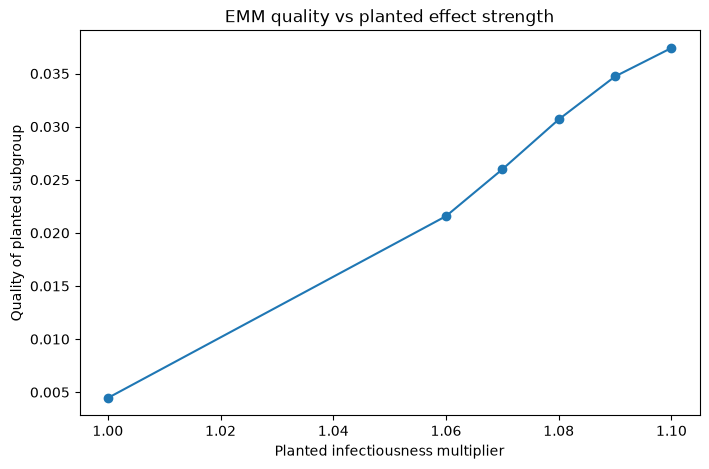

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    effect_strength_df["multiplier"],
    effect_strength_df["target_quality"],
    marker="o",
)

plt.xlabel("Planted infectiousness multiplier")
plt.ylabel("Quality of planted subgroup")
plt.title(
    "EMM quality vs planted effect strength"
)

plt.show()

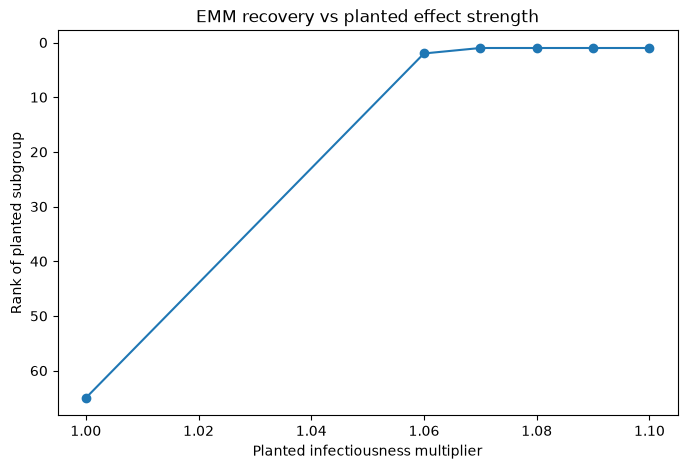

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    effect_strength_df["multiplier"],
    effect_strength_df["target_rank"],
    marker="o",
)

plt.xlabel("Planted infectiousness multiplier")
plt.ylabel("Rank of planted subgroup")
plt.title(
    "EMM recovery vs planted effect strength"
)

plt.gca().invert_yaxis()

plt.show()

In [37]:
EFFECT_STRENGTHS = [
    1.00,
    1.04,
    1.05,
    1.06,
    1.07,
    1.08,
    1.10,
]

N_BATCHES = 10
RUNS_PER_BATCH = 500

PLANTED_DESCRIPTION = "smoking == 1 AND age >= 60"

In [38]:
N_BATCHES = 10

In [39]:
def run_ensemble_from_design(
    params,
    seed_sets,
    run_rng_seeds,
):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]

In [40]:
robustness_rows = []

degree = graph.degree()

# One master seed makes the complete experiment reproducible.
master_seed_sequence = np.random.SeedSequence(20261012)

batch_sequences = master_seed_sequence.spawn(
    N_BATCHES
)

for batch_idx, batch_sequence in enumerate(
    batch_sequences
):
    print(
        f"\nBatch {batch_idx + 1}/{N_BATCHES}"
    )

    # Separate random streams for:
    # 1. choosing initial infected nodes
    # 2. epidemic simulation randomness
    seed_sequence, epidemic_sequence = (
        batch_sequence.spawn(2)
    )

    seed_rng = np.random.default_rng(
        seed_sequence
    )

    epidemic_rng = np.random.default_rng(
        epidemic_sequence
    )

    # New epidemic starting nodes for this batch
    seed_sets = [
        np.sort(
            seed_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(RUNS_PER_BATCH)
    ]

    # New simulation RNG seeds for this batch
    run_rng_seeds = epidemic_rng.integers(
        0,
        2**32 - 1,
        size=RUNS_PER_BATCH,
        dtype=np.uint32,
    )

    # IMPORTANT:
    # seed_sets and run_rng_seeds stay identical
    # across all multipliers inside this batch.

    for multiplier in EFFECT_STRENGTHS:

        print(
            f"  multiplier = {multiplier:.2f}"
        )

        current_params = base_params.scaled(
            planted_mask,
            infectiousness=multiplier,
        )

        current_runs = run_ensemble_from_design(
            current_params,
            seed_sets,
            run_rng_seeds,
        )

        final_sizes = np.array(
            [
                run.final_size
                for run in current_runs
            ]
        )

        (
            infection_count,
            mean_secondary,
        ) = per_node_spreading_metrics(
            current_runs
        )

        baseline = fit_degree_baseline(
            degree,
            mean_secondary,
        )

        current_df = people.copy()

        current_df["degree"] = degree

        current_df["infection_count"] = (
            infection_count
        )

        current_df["mean_secondary"] = (
            mean_secondary
        )

        current_df["expected_spread"] = (
            baseline.expected
        )

        current_df["residual"] = (
            baseline.residuals
        )

        results = search_subgroups(
            current_df,
            target_column="residual",
            categorical_columns=CATEGORICAL_COLUMNS,
            age_column="age",
            age_thresholds=range(20, 81, 5),
            min_size=20,
            max_depth=2,
            direction="high",
        )

        # Keep the same pair-only ranking definition
        # used in our previous experiment.
        pairs = (
            results[
                results["depth"] == 2
            ]
            .reset_index(drop=True)
        )

        target_match = pairs[
            pairs["description"]
            == PLANTED_DESCRIPTION
        ]

        if len(target_match) > 0:

            target_rank = int(
                target_match.index[0] + 1
            )

            target_quality = float(
                target_match.iloc[0][
                    "quality"
                ]
            )

        else:

            target_rank = np.nan
            target_quality = np.nan

        top_result = pairs.iloc[0]

        planted_mean_residual = (
            np.nanmean(
                baseline.residuals[
                    planted_mask
                ]
            )
        )

        nonplanted_mean_residual = (
            np.nanmean(
                baseline.residuals[
                    ~planted_mask
                ]
            )
        )

        robustness_rows.append(
            {
                "batch": batch_idx + 1,
                "multiplier": multiplier,

                "mean_fraction_infected":
                    final_sizes.mean()
                    / N_NODES,

                "residual_difference":
                    planted_mean_residual
                    - nonplanted_mean_residual,

                "target_rank":
                    target_rank,

                "target_quality":
                    target_quality,

                "top_description":
                    top_result[
                        "description"
                    ],

                "top_quality":
                    float(
                        top_result[
                            "quality"
                        ]
                    ),

                "exact_recovery":
                    target_rank == 1,

                "top5_recovery":
                    target_rank <= 5,
            }
        )

robustness_df = pd.DataFrame(
    robustness_rows
)

robustness_df.head(20)


Batch 1/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 2/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 3/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 4/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 5/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 6/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 7/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1

,batch,multiplier,mean_fraction_infected,residual_difference,target_rank,target_quality,top_description,top_quality,exact_recovery,top5_recovery
0,1,1.00,0.479332,0.007592,106,0.002597,alcohol == 1 AND age < 60,0.010570,False,False
1,1,1.04,0.487414,0.040950,8,0.014007,smoking == 1 AND age >= 30,0.020791,False,False
2,1,1.05,0.491292,0.043855,9,0.015001,smoking == 1 AND age >= 30,0.020854,False,False
3,1,1.06,0.495348,0.052960,6,0.018115,smoking == 1 AND age >= 30,0.020748,False,False
4,1,1.07,0.495858,0.059489,2,0.020348,smoking == 1 AND age >= 40,0.020617,False,True
5,1,1.08,0.496812,0.073835,2,0.025256,smoking == 1 AND age >= 40,0.025846,False,True
6,1,1.10,0.500880,0.092120,1,0.031510,smoking == 1 AND age >= 60,0.031510,True,True
7,2,1.00,0.497416,0.017868,56,0.006112,smoking == 1 AND obesity == 0,0.014293,False,False
8,2,1.04,0.502846,0.052487,1,0.017953,smoking == 1 AND age >= 60,0.017953,True,True
9,2,1.05,0.504890,0.061120,1,0.020906,smoking == 1 AND age >= 60,0.020906,True,True


In [41]:
robustness_summary = (
    robustness_df
    .groupby("multiplier")
    .agg(
        n_batches=(
            "batch",
            "count",
        ),

        mean_fraction_infected=(
            "mean_fraction_infected",
            "mean",
        ),

        mean_residual_difference=(
            "residual_difference",
            "mean",
        ),

        mean_target_rank=(
            "target_rank",
            "mean",
        ),

        median_target_rank=(
            "target_rank",
            "median",
        ),

        best_rank=(
            "target_rank",
            "min",
        ),

        worst_rank=(
            "target_rank",
            "max",
        ),

        mean_target_quality=(
            "target_quality",
            "mean",
        ),

        sd_target_quality=(
            "target_quality",
            "std",
        ),

        exact_recovery_rate=(
            "exact_recovery",
            "mean",
        ),

        top5_recovery_rate=(
            "top5_recovery",
            "mean",
        ),
    )
    .reset_index()
)

robustness_summary[
    "exact_recovery_rate_pct"
] = (
    100
    * robustness_summary[
        "exact_recovery_rate"
    ]
)

robustness_summary[
    "top5_recovery_rate_pct"
] = (
    100
    * robustness_summary[
        "top5_recovery_rate"
    ]
)

robustness_summary

,multiplier,n_batches,mean_fraction_infected,mean_residual_difference,mean_target_rank,median_target_rank,best_rank,worst_rank,mean_target_quality,sd_target_quality,exact_recovery_rate,top5_recovery_rate,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,10,0.486306,0.008489,119.5,124.0,52,213,0.002904,0.002726,0.0,0.0,0.0,0.0
1,1.04,10,0.492941,0.046629,6.8,7.0,1,17,0.015950,0.001890,0.2,0.4,20.0,40.0
2,1.05,10,0.494828,0.054900,4.3,4.5,1,9,0.018779,0.002337,0.4,0.7,40.0,70.0
3,1.06,10,0.496842,0.063194,3.3,2.0,1,9,0.021616,0.002004,0.4,0.7,40.0,70.0
4,1.07,10,0.498498,0.072492,1.8,1.0,1,6,0.024796,0.002695,0.7,0.9,70.0,90.0
5,1.08,10,0.500047,0.082168,2.0,1.0,1,9,0.028106,0.003242,0.7,0.9,70.0,90.0
6,1.10,10,0.502644,0.096129,1.0,1.0,1,1,0.032881,0.002544,1.0,1.0,100.0,100.0


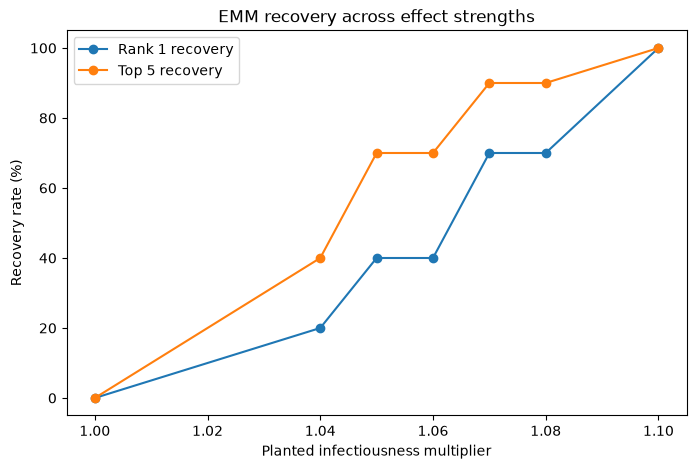

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    robustness_summary["multiplier"],
    robustness_summary[
        "exact_recovery_rate_pct"
    ],
    marker="o",
    label="Rank 1 recovery",
)

plt.plot(
    robustness_summary["multiplier"],
    robustness_summary[
        "top5_recovery_rate_pct"
    ],
    marker="o",
    label="Top 5 recovery",
)

plt.xlabel(
    "Planted infectiousness multiplier"
)

plt.ylabel(
    "Recovery rate (%)"
)

plt.title(
    "EMM recovery across effect strengths"
)

plt.ylim(-5, 105)

plt.legend()

plt.show()

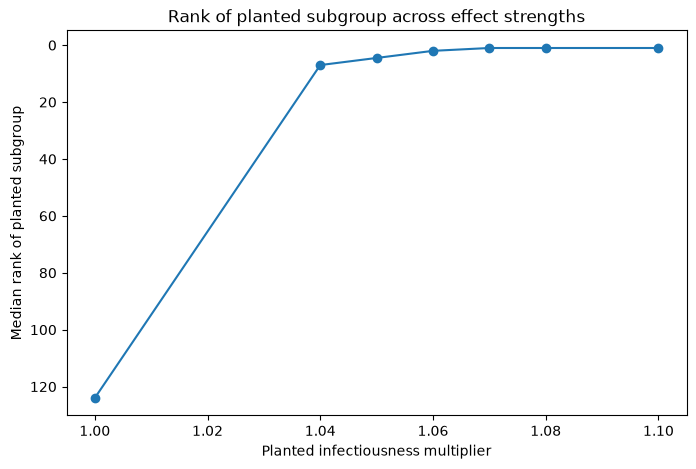

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    robustness_summary["multiplier"],
    robustness_summary[
        "median_target_rank"
    ],
    marker="o",
)

plt.xlabel(
    "Planted infectiousness multiplier"
)

plt.ylabel(
    "Median rank of planted subgroup"
)

plt.title(
    "Rank of planted subgroup across effect strengths"
)

plt.gca().invert_yaxis()

plt.show()

In [45]:
control_model_b = model_b_observations(
    graph,
    control_runs,
    susceptibility=infection_rate,
)

planted_model_b = model_b_observations(
    graph,
    planted_runs,
    susceptibility=infection_rate,
)

print(
    "Control Model B observations:",
    len(control_model_b.node_index),
)

print(
    "Planted Model B observations:",
    len(planted_model_b.node_index),
)

Control Model B observations: 245667
Planted Model B observations: 288198


In [46]:
def model_b_to_dataframe(observations):
    df = pd.DataFrame(
        {
            "run": observations.run_index,
            "node_id": observations.node_index,
            "offspring": observations.offspring,
            "opportunity": observations.opportunity,
            "descendants": observations.descendants,
        }
    )

    descriptor_columns = [
        "age",
        "sex",
        "occupation",
        "smoking",
        "alcohol",
        "obesity",
    ]

    node_index = observations.node_index

    for column in descriptor_columns:
        df[column] = people.iloc[node_index][column].to_numpy()

    # Ground truth is added only for evaluation/sanity checks.
    # It must not be used as an EMM descriptor.
    df["is_planted"] = planted_mask[node_index]

    df["offspring_per_opportunity"] = np.divide(
        df["offspring"].to_numpy(dtype=np.float64),
        df["opportunity"].to_numpy(dtype=np.float64),
        out=np.full(len(df), np.nan, dtype=np.float64),
        where=df["opportunity"].to_numpy() > 0,
    )

    return df


control_model_b_df = model_b_to_dataframe(
    control_model_b
)

planted_model_b_df = model_b_to_dataframe(
    planted_model_b
)

planted_model_b_df.head()


,run,node_id,offspring,opportunity,descendants,age,sex,occupation,smoking,alcohol,obesity,is_planted,offspring_per_opportunity
0,0,0,0,20,0,62,Female,Student,0,0,0,False,0.000000
1,0,1,3,56,7,71,Female,Office-based,0,0,0,False,0.053571
2,0,2,2,10,33,40,Male,Agriculture,1,1,1,False,0.200000
3,0,4,0,10,0,54,Male,Healthcare,0,0,0,False,0.000000
4,0,5,0,8,0,13,Male,Student,0,1,0,False,0.000000


In [47]:
# Sanity checks for the extracted Model B quantities.

assert np.all(
    control_model_b.offspring
    <= control_model_b.opportunity
)
assert np.all(
    planted_model_b.offspring
    <= planted_model_b.opportunity
)

assert np.all(
    control_model_b.descendants
    >= control_model_b.offspring
)
assert np.all(
    planted_model_b.descendants
    >= planted_model_b.offspring
)

print(
    "Control zero-opportunity observations:",
    (control_model_b_df["opportunity"] == 0).sum(),
)
print(
    "Planted zero-opportunity observations:",
    (planted_model_b_df["opportunity"] == 0).sum(),
)

planted_model_b_df[
    ["offspring", "opportunity", "descendants"]
].describe()


Control zero-opportunity observations: 94
Planted zero-opportunity observations: 242


,offspring,opportunity,descendants
count,288198.000000,288198.000000,288198.000000
mean,0.986804,23.774332,8.771286
std,1.248757,19.603693,32.735898
min,0.000000,0.000000,0.000000
25%,0.000000,11.000000,0.000000
50%,1.000000,17.000000,1.000000
75%,1.000000,31.000000,5.000000
max,14.000000,265.000000,668.000000


In [48]:
def pooled_model_b_rates(df):
    summary = (
        df.groupby("is_planted")
        .agg(
            observations=("node_id", "size"),
            total_offspring=("offspring", "sum"),
            total_opportunity=("opportunity", "sum"),
            mean_descendants=("descendants", "mean"),
        )
    )

    summary["offspring_per_opportunity"] = (
        summary["total_offspring"]
        / summary["total_opportunity"]
    )

    return summary


print("Control")
display(
    pooled_model_b_rates(
        control_model_b_df
    )
)

print("Planted")
display(
    pooled_model_b_rates(
        planted_model_b_df
    )
)


Control


,observations,total_offspring,total_opportunity,mean_descendants,offspring_per_opportunity
is_planted,,,,,
False,212507,209962,5490906,9.909843,0.038238
True,33160,32159,841342,10.493758,0.038223


Planted


,observations,total_offspring,total_opportunity,mean_descendants,offspring_per_opportunity
is_planted,,,,,
False,250240,227512,5989089,8.036677,0.037988
True,37958,56883,862626,13.614232,0.065942


In [49]:
import statsmodels.api as sm

In [50]:
model_b_fit_df = planted_model_b_df[
    planted_model_b_df["opportunity"] > 0
].copy()

model_b_fit_df["log_opportunity"] = np.log(
    model_b_fit_df["opportunity"]
)

model_b_fit_df["group"] = (
    model_b_fit_df["is_planted"]
    .astype(int)
)

In [51]:
X = sm.add_constant(
    model_b_fit_df[["group"]]
)

model_b_nb = sm.GLM(
    model_b_fit_df["offspring"],
    X,
    family=sm.families.NegativeBinomial(),
    offset=model_b_fit_df["log_opportunity"],
)

model_b_result = model_b_nb.fit()

print(model_b_result.summary())

C:\Users\User\AppData\Local\Temp\ipykernel_20048\3285573212.py:8: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


                 Generalized Linear Model Regression Results                  
Dep. Variable:              offspring   No. Observations:               287956
Model:                            GLM   Df Residuals:                   287954
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -3.6019e+05
Date:                Sun, 18 Oct 2026   Deviance:                   1.7621e+05
Time:                        23:14:04   Pearson chi2:                 1.59e+05
No. Iterations:                     5   Pseudo R-squ. (CS):            0.01787
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.2563      0.003  -1054.810      0.0

In [52]:
beta_group = model_b_result.params["group"]

rate_ratio = np.exp(beta_group)

print(
    "Group coefficient:",
    beta_group
)

print(
    "Transmission rate ratio:",
    rate_ratio
)

Group coefficient: 0.550239220041636
Transmission rate ratio: 1.7336676963242164


In [53]:
control_fit_df = control_model_b_df[
    control_model_b_df["opportunity"] > 0
].copy()

control_fit_df["log_opportunity"] = np.log(
    control_fit_df["opportunity"]
)

control_fit_df["group"] = (
    control_fit_df["is_planted"]
    .astype(int)
)

X_control = sm.add_constant(
    control_fit_df[["group"]]
)

control_nb = sm.GLM(
    control_fit_df["offspring"],
    X_control,
    family=sm.families.NegativeBinomial(),
    offset=control_fit_df["log_opportunity"],
)

control_result = control_nb.fit()

print(
    "CONTROL rate ratio:",
    np.exp(
        control_result.params["group"]
    )
)

C:\Users\User\AppData\Local\Temp\ipykernel_20048\386345837.py:21: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


CONTROL rate ratio: 1.0010609537592925


In [54]:
X = sm.add_constant(
    model_b_fit_df[["group"]]
)

model_b_nb = sm.NegativeBinomial(
    model_b_fit_df["offspring"],
    X,
    exposure=model_b_fit_df["opportunity"],
)

model_b_result = model_b_nb.fit()

print(model_b_result.summary())

Optimization terminated successfully.
         Current function value: 1.156674
         Iterations: 16
         Function evaluations: 18
         Gradient evaluations: 18
                     NegativeBinomial Regression Results                      
Dep. Variable:              offspring   No. Observations:               287956
Model:               NegativeBinomial   Df Residuals:                   287954
Method:                           MLE   Df Model:                            1
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                 0.01811
Time:                        23:14:11   Log-Likelihood:            -3.3307e+05
converged:                       True   LL-Null:                   -3.3921e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.2705      0.002  -155

In [55]:
beta_group = model_b_result.params["group"]
rate_ratio = np.exp(beta_group)

print("Group coefficient:", beta_group)
print("Transmission rate ratio:", rate_ratio)
print("Estimated alpha:", model_b_result.params["alpha"])

Group coefficient: 0.5514742516919016
Transmission rate ratio: 1.735810153529124
Estimated alpha: 7.437411416905118e-05


In [56]:
X_control = sm.add_constant(
    control_fit_df[["group"]]
)

control_nb = sm.NegativeBinomial(
    control_fit_df["offspring"],
    X_control,
    exposure=control_fit_df["opportunity"],
)

control_result = control_nb.fit()

print(
    "CONTROL rate ratio:",
    np.exp(
        control_result.params["group"]
    )
)

print(
    "CONTROL alpha:",
    control_result.params["alpha"]
)

Optimization terminated successfully.
         Current function value: 1.168207
         Iterations: 20
         Function evaluations: 22
         Gradient evaluations: 22
CONTROL rate ratio: 0.9996052761317133
CONTROL alpha: 6.7125771180417055e-06


In [57]:
X = sm.add_constant(
    model_b_fit_df[["group"]]
)

poisson_model = sm.GLM(
    model_b_fit_df["offspring"],
    X,
    family=sm.families.Poisson(),
    offset=model_b_fit_df["log_opportunity"],
)

poisson_result = poisson_model.fit()

print(poisson_result.summary())

print(
    "POISSON planted rate ratio:",
    np.exp(poisson_result.params["group"])
)

print(
    "AIC:",
    poisson_result.aic
)

                 Generalized Linear Model Regression Results                  
Dep. Variable:              offspring   No. Observations:               287956
Model:                            GLM   Df Residuals:                   287954
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -3.3307e+05
Date:                Sun, 18 Oct 2026   Deviance:                   2.8916e+05
Time:                        23:14:14   Pearson chi2:                 2.82e+05
No. Iterations:                     5   Pseudo R-squ. (CS):            0.04197
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.2705      0.002  -1559.966      0.0

In [58]:
X_control = sm.add_constant(
    control_fit_df[["group"]]
)

control_poisson = sm.GLM(
    control_fit_df["offspring"],
    X_control,
    family=sm.families.Poisson(),
    offset=control_fit_df["log_opportunity"],
)

control_poisson_result = (
    control_poisson.fit()
)

print(
    "POISSON control rate ratio:",
    np.exp(
        control_poisson_result.params["group"]
    )
)

print(
    "AIC:",
    control_poisson_result.aic
)

POISSON control rate ratio: 0.9996161731788485
AIC: 573763.9460948717


In [59]:
pearson_dispersion = (
    np.sum(
        poisson_result.resid_pearson ** 2
    )
    / poisson_result.df_resid
)

print(
    "Poisson Pearson dispersion:",
    pearson_dispersion
)

Poisson Pearson dispersion: 0.9797783778045126


In [60]:
MODEL_B_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]

model_b_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=20,
    max_depth=2,
    direction="high",
)

model_b_results.head(20)

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,117,0.117,37958,250240,raw,56883.0,862626.0,0.065942,227512.0,5989089.0,0.037988,1.735867,0.551507,0.188644
1,2,smoking == 1 AND age >= 55,151,0.151,49467,238731,raw,67613.0,1146580.0,0.058969,216782.0,5705135.0,0.037998,1.551917,0.439491,0.170781
2,1,age >= 60,192,0.192,60348,227850,raw,76993.0,1386471.0,0.055532,207402.0,5465244.0,0.037949,1.463312,0.380703,0.166816
3,2,obesity == 0 AND age >= 60,183,0.183,57408,230790,raw,73546.0,1328440.0,0.055363,210849.0,5523275.0,0.038175,1.450248,0.371734,0.159022
4,2,smoking == 1 AND age >= 50,185,0.185,60736,227462,raw,78570.0,1433423.0,0.054813,205825.0,5418292.0,0.037987,1.442935,0.366679,0.157715
5,2,smoking == 1 AND age >= 45,218,0.218,71170,217028,raw,87699.0,1680426.0,0.052189,196696.0,5171289.0,0.038036,1.372077,0.316326,0.147694
6,1,age >= 55,254,0.254,80516,207682,raw,95625.0,1881642.0,0.050820,188770.0,4970073.0,0.037981,1.338025,0.291195,0.146757
7,2,smoking == 1 AND age >= 40,256,0.256,82527,205671,raw,97838.0,1939454.0,0.050446,186557.0,4912261.0,0.037978,1.328305,0.283904,0.143645
8,2,smoking == 1 AND age >= 35,296,0.296,94162,194036,raw,108245.0,2209055.0,0.049001,176150.0,4642660.0,0.037942,1.291474,0.255784,0.139162
9,2,obesity == 0 AND age >= 55,241,0.241,76281,211917,raw,91030.0,1793499.0,0.050756,193365.0,5058216.0,0.038228,1.327709,0.283455,0.139153


In [61]:
PLANTED_DESCRIPTION = (
    "smoking == 1 AND age >= 60"
)

target = model_b_results[
    model_b_results["description"]
    == PLANTED_DESCRIPTION
]

target

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,117,0.117,37958,250240,raw,56883.0,862626.0,0.065942,227512.0,5989089.0,0.037988,1.735867,0.551507,0.188644


In [62]:
target_rank = (
    target.index[0] + 1
)

print(
    "Model B planted subgroup rank:",
    target_rank,
)

print(
    "Estimated rate ratio:",
    target.iloc[0]["rate_ratio"],
)

print(
    "Log rate ratio:",
    target.iloc[0]["log_rate_ratio"],
)

print(
    "Quality:",
    target.iloc[0]["quality"],
)

Model B planted subgroup rank: 1
Estimated rate ratio: 1.7358668430895934
Log rate ratio: 0.551506910006906
Quality: 0.18864438766867084


In [63]:
control_model_b_results = search_model_b_subgroups(
    people,
    control_model_b,
    categorical_columns=MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
)

control_model_b_results.head(20)

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,occupation == Office-based AND age < 35,78,0.078,16815,228852,raw,17184.0,433858.0,0.039607,224937.0,5898390.0,0.038135,1.038602,0.037876,0.010578
1,2,smoking == 1 AND age < 65,529,0.529,135567,110100,raw,134699.0,3501559.0,0.038468,107422.0,2830689.0,0.037949,1.013682,0.013590,0.009884
2,2,occupation == Office-based AND age < 45,97,0.097,21718,223949,raw,22669.0,576083.0,0.039350,219452.0,5756165.0,0.038125,1.032146,0.031640,0.009854
3,2,occupation == Office-based AND age < 30,69,0.069,14808,230859,raw,15073.0,381298.0,0.039531,227048.0,5950950.0,0.038153,1.036105,0.035469,0.009317
4,2,occupation == Office-based AND smoking == 1,103,0.103,26302,219365,raw,26625.0,678810.0,0.039223,215496.0,5653438.0,0.038118,1.028999,0.028586,0.009174
5,2,occupation == Office-based AND age < 40,86,0.086,18953,226714,raw,19564.0,497479.0,0.039326,222557.0,5834769.0,0.038143,1.031016,0.030545,0.008957
6,1,smoking == 1,599,0.599,155191,90476,raw,152920.0,3983034.0,0.038393,89201.0,2349214.0,0.037971,1.011121,0.011060,0.008560
7,2,occupation == Office-based AND age < 50,107,0.107,24134,221533,raw,24794.0,633596.0,0.039132,217327.0,5698652.0,0.038137,1.026107,0.025772,0.008430
8,2,smoking == 1 AND age < 70,563,0.563,144930,100737,raw,143139.0,3726601.0,0.038410,98982.0,2605647.0,0.037987,1.011124,0.011063,0.008301
9,2,occupation == Office-based AND age < 25,58,0.058,12366,233301,raw,12739.0,322880.0,0.039454,229382.0,6009368.0,0.038171,1.033627,0.033074,0.007965


In [64]:
control_target = control_model_b_results[
    control_model_b_results["description"]
    == PLANTED_DESCRIPTION
]

control_target_rank = (
    control_target.index[0] + 1
)

print(
    "CONTROL Model B planted subgroup rank:",
    control_target_rank,
)

print(
    "CONTROL estimated rate ratio:",
    control_target.iloc[0]["rate_ratio"],
)

print(
    "CONTROL log rate ratio:",
    control_target.iloc[0]["log_rate_ratio"],
)

print(
    "CONTROL quality:",
    control_target.iloc[0]["quality"],
)

CONTROL Model B planted subgroup rank: 184
CONTROL estimated rate ratio: 0.9996161731788491
CONTROL log rate ratio: -0.0003839005015194894
CONTROL quality: -0.00013131417525472685


In [66]:
current_model_b = model_b_observations(
    graph,
    current_runs,
    susceptibility=infection_rate,
)

results = search_model_b_subgroups(
    people,
    current_model_b,
    categorical_columns=MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
)

In [67]:
EFFECT_STRENGTHS = [
    1.00,
    1.04,
    1.05,
    1.06,
    1.07,
    1.08,
    1.10,
]

N_MODEL_B_BATCHES = 10
RUNS_PER_BATCH = 500

PLANTED_DESCRIPTION = (
    "smoking == 1 AND age >= 60"
)

MODEL_B_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]

In [68]:
def run_ensemble_from_design(
    params,
    seed_sets,
    run_rng_seeds,
):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]

In [77]:
model_b_robustness_rows = []

master_seed_sequence = np.random.SeedSequence(
    20261012
)

batch_sequences = master_seed_sequence.spawn(
    N_MODEL_B_BATCHES
)

for batch_idx, batch_sequence in enumerate(
    batch_sequences
):

    print(
        f"\nBatch "
        f"{batch_idx + 1}/"
        f"{N_MODEL_B_BATCHES}"
    )

    (
        seed_sequence,
        epidemic_sequence,
    ) = batch_sequence.spawn(2)

    seed_rng = np.random.default_rng(
        seed_sequence
    )

    epidemic_rng = np.random.default_rng(
        epidemic_sequence
    )

    # Same initial infections for every
    # multiplier within this batch.
    seed_sets = [
        np.sort(
            seed_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(
            RUNS_PER_BATCH
        )
    ]

    # Same simulation RNG seeds for every
    # multiplier within this batch.
    run_rng_seeds = (
        epidemic_rng.integers(
            0,
            2**32 - 1,
            size=RUNS_PER_BATCH,
            dtype=np.uint32,
        )
    )

    for multiplier in EFFECT_STRENGTHS:

        print(
            f"  multiplier = "
            f"{multiplier:.2f}"
        )

        current_params = (
            base_params.scaled(
                planted_mask,
                infectiousness=multiplier,
            )
        )

        current_runs = (
            run_ensemble_from_design(
                current_params,
                seed_sets,
                run_rng_seeds,
            )
        )

        # Overall epidemic size.
        final_sizes = np.array(
            [
                run.final_size
                for run in current_runs
            ]
        )

        # Extract Model B observations:
        # offspring, raw opportunity,
        # susceptibility-weighted opportunity,
        # descendants, node/run ids.
        current_model_b = (
            model_b_observations(
                graph,
                current_runs,
                susceptibility=infection_rate,
            )
        )

        # Run the complete susceptibility-weighted
        # Model B EMM search across depth 1 and 2.
        results = (
            search_model_b_subgroups(
                people,
                current_model_b,
                categorical_columns=(
                    MODEL_B_CATEGORICAL_COLUMNS
                ),
                age_column="age",
                age_thresholds=range(
                    20,
                    81,
                    5,
                ),
                min_size=20,
                max_depth=2,
                direction="high",
                opportunity_type="weighted",
            )
        )

        target_match = results[
            results["description"]
            == PLANTED_DESCRIPTION
        ]

        if len(target_match) > 0:

            target_rank = int(
                target_match.index[0]
                + 1
            )

            target_rate_ratio = float(
                target_match.iloc[0][
                    "rate_ratio"
                ]
            )

            target_log_rate_ratio = float(
                target_match.iloc[0][
                    "log_rate_ratio"
                ]
            )

            target_quality = float(
                target_match.iloc[0][
                    "quality"
                ]
            )

        else:

            target_rank = np.nan
            target_rate_ratio = np.nan
            target_log_rate_ratio = np.nan
            target_quality = np.nan

        top_result = results.iloc[0]

        model_b_robustness_rows.append(
            {
                "batch":
                    batch_idx + 1,

                "multiplier":
                    multiplier,

                "mean_fraction_infected":
                    final_sizes.mean()
                    / N_NODES,

                "target_rank":
                    target_rank,

                "target_rate_ratio":
                    target_rate_ratio,

                "target_log_rate_ratio":
                    target_log_rate_ratio,

                "target_quality":
                    target_quality,

                "top_description":
                    top_result[
                        "description"
                    ],

                "top_rate_ratio":
                    float(
                        top_result[
                            "rate_ratio"
                        ]
                    ),

                "top_quality":
                    float(
                        top_result[
                            "quality"
                        ]
                    ),

                "exact_recovery":
                    target_rank == 1,

                "top5_recovery":
                    target_rank <= 5,
            }
        )


model_b_robustness_df = pd.DataFrame(
    model_b_robustness_rows
)

model_b_robustness_df.head(20)


Batch 1/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 2/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 3/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 4/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 5/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 6/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 7/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1

,batch,multiplier,mean_fraction_infected,target_rank,target_rate_ratio,target_log_rate_ratio,target_quality,top_description,top_rate_ratio,top_quality,exact_recovery,top5_recovery
0,1,1.00,0.479332,322,0.995637,-0.004372,-0.001496,age < 65,1.006367,0.005964,False,False
1,1,1.04,0.487414,1,1.036247,0.035605,0.012179,smoking == 1 AND age >= 60,1.036247,0.012179,True,True
2,1,1.05,0.491292,1,1.048643,0.047497,0.016247,smoking == 1 AND age >= 60,1.048643,0.016247,True,True
3,1,1.06,0.495348,1,1.055775,0.054275,0.018565,smoking == 1 AND age >= 60,1.055775,0.018565,True,True
4,1,1.07,0.495858,1,1.064330,0.062346,0.021326,smoking == 1 AND age >= 60,1.064330,0.021326,True,True
5,1,1.08,0.496812,1,1.074769,0.072106,0.024664,smoking == 1 AND age >= 60,1.074769,0.024664,True,True
6,1,1.10,0.500880,1,1.093901,0.089751,0.030699,smoking == 1 AND age >= 60,1.093901,0.030699,True,True
7,2,1.00,0.497416,169,1.001083,0.001082,0.000370,age < 70,1.011407,0.011009,False,False
8,2,1.04,0.502846,1,1.045080,0.044094,0.015082,smoking == 1 AND age >= 60,1.045080,0.015082,True,True
9,2,1.05,0.504890,1,1.050019,0.048808,0.016695,smoking == 1 AND age >= 60,1.050019,0.016695,True,True


In [78]:
model_b_robustness_summary = (
    model_b_robustness_df
    .groupby("multiplier")
    .agg(
        n_batches=(
            "batch",
            "count",
        ),

        mean_fraction_infected=(
            "mean_fraction_infected",
            "mean",
        ),

        mean_target_rank=(
            "target_rank",
            "mean",
        ),

        median_target_rank=(
            "target_rank",
            "median",
        ),

        best_rank=(
            "target_rank",
            "min",
        ),

        worst_rank=(
            "target_rank",
            "max",
        ),

        mean_rate_ratio=(
            "target_rate_ratio",
            "mean",
        ),

        sd_rate_ratio=(
            "target_rate_ratio",
            "std",
        ),

        mean_log_rate_ratio=(
            "target_log_rate_ratio",
            "mean",
        ),

        mean_quality=(
            "target_quality",
            "mean",
        ),

        sd_quality=(
            "target_quality",
            "std",
        ),

        exact_recovery_rate=(
            "exact_recovery",
            "mean",
        ),

        top5_recovery_rate=(
            "top5_recovery",
            "mean",
        ),
    )
    .reset_index()
)

model_b_robustness_summary[
    "exact_recovery_rate_pct"
] = (
    100
    * model_b_robustness_summary[
        "exact_recovery_rate"
    ]
)

model_b_robustness_summary[
    "top5_recovery_rate_pct"
] = (
    100
    * model_b_robustness_summary[
        "top5_recovery_rate"
    ]
)

model_b_robustness_summary

,multiplier,n_batches,mean_fraction_infected,mean_target_rank,median_target_rank,best_rank,worst_rank,mean_rate_ratio,sd_rate_ratio,mean_log_rate_ratio,mean_quality,sd_quality,exact_recovery_rate,top5_recovery_rate,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,10,0.486306,262.1,310.0,49,391,0.995986,0.006820,-0.004043,-0.001383,0.002342,0.0,0.0,0.0,0.0
1,1.04,10,0.492941,1.3,1.0,1,3,1.040359,0.005693,0.039552,0.013529,0.001872,0.8,1.0,80.0,100.0
2,1.05,10,0.494828,1.2,1.0,1,2,1.051835,0.006403,0.050519,0.017280,0.002077,0.8,1.0,80.0,100.0
3,1.06,10,0.496842,1.2,1.0,1,2,1.061303,0.005109,0.059487,0.020348,0.001647,0.8,1.0,80.0,100.0
4,1.07,10,0.498498,1.0,1.0,1,1,1.071482,0.006276,0.069027,0.023611,0.002004,1.0,1.0,100.0,100.0
5,1.08,10,0.500047,1.0,1.0,1,1,1.080545,0.007297,0.077445,0.026490,0.002307,1.0,1.0,100.0,100.0
6,1.10,10,0.502644,1.0,1.0,1,1,1.097683,0.004419,0.093194,0.031877,0.001376,1.0,1.0,100.0,100.0


In [79]:
model_b_robustness_summary[
    [
        "multiplier",
        "mean_rate_ratio",
        "sd_rate_ratio",
    ]
]

,multiplier,mean_rate_ratio,sd_rate_ratio
0,1.00,0.995986,0.006820
1,1.04,1.040359,0.005693
2,1.05,1.051835,0.006403
3,1.06,1.061303,0.005109
4,1.07,1.071482,0.006276
5,1.08,1.080545,0.007297
6,1.10,1.097683,0.004419


In [80]:
model_b_robustness_summary[
    [
        "multiplier",
        "median_target_rank",
        "worst_rank",
        "exact_recovery_rate_pct",
        "top5_recovery_rate_pct",
    ]
]

,multiplier,median_target_rank,worst_rank,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,310.0,391,0.0,0.0
1,1.04,1.0,3,80.0,100.0
2,1.05,1.0,2,80.0,100.0
3,1.06,1.0,2,80.0,100.0
4,1.07,1.0,1,100.0,100.0
5,1.08,1.0,1,100.0,100.0
6,1.10,1.0,1,100.0,100.0


In [81]:
comparison_df = (
    robustness_summary[
        [
            "multiplier",
            "median_target_rank",
            "exact_recovery_rate_pct",
            "top5_recovery_rate_pct",
        ]
    ]
    .rename(
        columns={
            "median_target_rank":
                "baseline_median_rank",

            "exact_recovery_rate_pct":
                "baseline_exact_pct",

            "top5_recovery_rate_pct":
                "baseline_top5_pct",
        }
    )
    .merge(
        model_b_robustness_summary[
            [
                "multiplier",
                "median_target_rank",
                "exact_recovery_rate_pct",
                "top5_recovery_rate_pct",
                "mean_rate_ratio",
            ]
        ].rename(
            columns={
                "median_target_rank":
                    "model_b_median_rank",

                "exact_recovery_rate_pct":
                    "model_b_exact_pct",

                "top5_recovery_rate_pct":
                    "model_b_top5_pct",
            }
        ),
        on="multiplier",
    )
)

comparison_df

,multiplier,baseline_median_rank,baseline_exact_pct,baseline_top5_pct,model_b_median_rank,model_b_exact_pct,model_b_top5_pct,mean_rate_ratio
0,1.00,124.0,0.0,0.0,310.0,0.0,0.0,0.995986
1,1.04,7.0,20.0,40.0,1.0,80.0,100.0,1.040359
2,1.05,4.5,40.0,70.0,1.0,80.0,100.0,1.051835
3,1.06,2.0,40.0,70.0,1.0,80.0,100.0,1.061303
4,1.07,1.0,70.0,90.0,1.0,100.0,100.0,1.071482
5,1.08,1.0,70.0,90.0,1.0,100.0,100.0,1.080545
6,1.10,1.0,100.0,100.0,1.0,100.0,100.0,1.097683


In [82]:
control_model_b = model_b_observations(
    graph,
    control_runs,
    susceptibility=infection_rate,
)

planted_model_b = model_b_observations(
    graph,
    planted_runs,
    susceptibility=infection_rate,
)

In [83]:
print(
    planted_model_b.weighted_opportunity[:10]
)

print(
    planted_model_b.opportunity[:10]
)

[ 6.4486 17.7766  3.4295  3.5211  2.3374  7.3727  2.8332  3.2242  8.1795
  7.4846]
[20 56 10 10  8 21  9  9 27 21]


In [84]:
raw_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
    opportunity_type="raw",
)

weighted_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
    opportunity_type="weighted",
)

In [85]:
weighted_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=20,
    max_depth=2,
    direction="high",
    opportunity_type="weighted",
)

weighted_target = weighted_results[
    weighted_results["description"]
    == PLANTED_DESCRIPTION
]

print(
    "WEIGHTED rank:",
    weighted_target.index[0] + 1,
)

print(
    "WEIGHTED RR:",
    weighted_target.iloc[0]["rate_ratio"],
)

print(
    "WEIGHTED log RR:",
    weighted_target.iloc[0]["log_rate_ratio"],
)

print(
    "WEIGHTED quality:",
    weighted_target.iloc[0]["quality"],
)

WEIGHTED rank: 1
WEIGHTED RR: 1.7518211770250602
WEIGHTED log RR: 0.5606559193968457
WEIGHTED quality: 0.19177383036979398


In [86]:
weighted_results.head(20)

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,117,0.117,37958,250240,weighted,56883.0,2.763889e+05,0.205808,227512.0,1.936565e+06,0.117482,1.751821,0.560656,0.191774
1,2,smoking == 1 AND age >= 55,151,0.151,49467,238731,weighted,67613.0,3.669543e+05,0.184255,216782.0,1.846000e+06,0.117433,1.569013,0.450447,0.175038
2,1,age >= 60,192,0.192,60348,227850,weighted,76993.0,4.458317e+05,0.172695,207402.0,1.767122e+06,0.117367,1.471411,0.386222,0.169234
3,2,smoking == 1 AND age >= 50,185,0.185,60736,227462,weighted,78570.0,4.592808e+05,0.171072,205825.0,1.753673e+06,0.117368,1.457568,0.376770,0.162055
4,2,obesity == 0 AND age >= 60,183,0.183,57408,230790,weighted,73546.0,4.266938e+05,0.172362,210849.0,1.786260e+06,0.118039,1.460212,0.378582,0.161951
5,2,smoking == 1 AND age >= 45,218,0.218,71170,217028,weighted,87699.0,5.385257e+05,0.162850,196696.0,1.674428e+06,0.117471,1.386306,0.326643,0.152511
6,1,age >= 55,254,0.254,80516,207682,weighted,95625.0,6.036026e+05,0.158424,188770.0,1.609351e+06,0.117296,1.350636,0.300575,0.151485
7,2,smoking == 1 AND age >= 40,256,0.256,82527,205671,weighted,97838.0,6.243158e+05,0.156712,186557.0,1.588638e+06,0.117432,1.334494,0.288552,0.145997
8,2,obesity == 0 AND age >= 55,241,0.241,76281,211917,weighted,91030.0,5.750011e+05,0.158313,193365.0,1.637953e+06,0.118053,1.341033,0.293440,0.144055
9,2,smoking == 1 AND age >= 35,296,0.296,94162,194036,weighted,108245.0,7.119214e+05,0.152046,176150.0,1.501033e+06,0.117353,1.295637,0.259002,0.140912


In [87]:
weighted_control_results = (
    search_model_b_subgroups(
        people,
        control_model_b,
        categorical_columns=
            MODEL_B_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(20, 81, 5),
        min_size=20,
        max_depth=2,
        direction="high",
        opportunity_type="weighted",
    )
)

weighted_control_target = (
    weighted_control_results[
        weighted_control_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL weighted rank:",
    weighted_control_target.index[0] + 1,
)

print(
    "CONTROL weighted RR:",
    weighted_control_target.iloc[0][
        "rate_ratio"
    ],
)

print(
    "CONTROL weighted quality:",
    weighted_control_target.iloc[0][
        "quality"
    ],
)

CONTROL weighted rank: 56
CONTROL weighted RR: 1.0061856085928524
CONTROL weighted quality: 0.002109286765583017


In [88]:
weighted_model_b_robustness_rows = []

master_seed_sequence = np.random.SeedSequence(
    20261012
)

batch_sequences = master_seed_sequence.spawn(
    N_MODEL_B_BATCHES
)

for batch_idx, batch_sequence in enumerate(
    batch_sequences
):

    print(
        f"\nBatch "
        f"{batch_idx + 1}/"
        f"{N_MODEL_B_BATCHES}"
    )

    (
        seed_sequence,
        epidemic_sequence,
    ) = batch_sequence.spawn(2)

    seed_rng = np.random.default_rng(
        seed_sequence
    )

    epidemic_rng = np.random.default_rng(
        epidemic_sequence
    )

    # Same initial seed sets for all
    # multipliers within this batch.
    seed_sets = [
        np.sort(
            seed_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(
            RUNS_PER_BATCH
        )
    ]

    # Same epidemic RNG seeds for all
    # multipliers within this batch.
    run_rng_seeds = (
        epidemic_rng.integers(
            0,
            2**32 - 1,
            size=RUNS_PER_BATCH,
            dtype=np.uint32,
        )
    )

    for multiplier in EFFECT_STRENGTHS:

        print(
            f"  multiplier = "
            f"{multiplier:.2f}"
        )

        current_params = (
            base_params.scaled(
                planted_mask,
                infectiousness=multiplier,
            )
        )

        current_runs = (
            run_ensemble_from_design(
                current_params,
                seed_sets,
                run_rng_seeds,
            )
        )

        final_sizes = np.array(
            [
                run.final_size
                for run in current_runs
            ]
        )

        # Model B observations with both
        # raw and susceptibility-weighted
        # opportunity.
        current_model_b = (
            model_b_observations(
                graph,
                current_runs,
                susceptibility=infection_rate,
            )
        )

        # Weighted Model B EMM.
        results = (
            search_model_b_subgroups(
                people,
                current_model_b,
                categorical_columns=(
                    MODEL_B_CATEGORICAL_COLUMNS
                ),
                age_column="age",
                age_thresholds=range(
                    20,
                    81,
                    5,
                ),
                min_size=20,
                max_depth=2,
                direction="high",
                opportunity_type="weighted",
            )
        )

        target_match = results[
            results["description"]
            == PLANTED_DESCRIPTION
        ]

        if len(target_match) > 0:

            target_rank = int(
                target_match.index[0]
                + 1
            )

            target_rate_ratio = float(
                target_match.iloc[0][
                    "rate_ratio"
                ]
            )

            target_log_rate_ratio = float(
                target_match.iloc[0][
                    "log_rate_ratio"
                ]
            )

            target_quality = float(
                target_match.iloc[0][
                    "quality"
                ]
            )

        else:

            target_rank = np.nan
            target_rate_ratio = np.nan
            target_log_rate_ratio = np.nan
            target_quality = np.nan

        top_result = results.iloc[0]

        weighted_model_b_robustness_rows.append(
            {
                "batch":
                    batch_idx + 1,

                "multiplier":
                    multiplier,

                "mean_fraction_infected":
                    final_sizes.mean()
                    / N_NODES,

                "target_rank":
                    target_rank,

                "target_rate_ratio":
                    target_rate_ratio,

                "target_log_rate_ratio":
                    target_log_rate_ratio,

                "target_quality":
                    target_quality,

                "top_description":
                    top_result[
                        "description"
                    ],

                "top_rate_ratio":
                    float(
                        top_result[
                            "rate_ratio"
                        ]
                    ),

                "top_quality":
                    float(
                        top_result[
                            "quality"
                        ]
                    ),

                "exact_recovery":
                    target_rank == 1,

                "top5_recovery":
                    target_rank <= 5,
            }
        )


weighted_model_b_robustness_df = pd.DataFrame(
    weighted_model_b_robustness_rows
)

weighted_model_b_robustness_df.head(20)


Batch 1/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 2/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 3/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 4/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 5/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 6/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 7/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1

,batch,multiplier,mean_fraction_infected,target_rank,target_rate_ratio,target_log_rate_ratio,target_quality,top_description,top_rate_ratio,top_quality,exact_recovery,top5_recovery
0,1,1.00,0.479332,322,0.995637,-0.004372,-0.001496,age < 65,1.006367,0.005964,False,False
1,1,1.04,0.487414,1,1.036247,0.035605,0.012179,smoking == 1 AND age >= 60,1.036247,0.012179,True,True
2,1,1.05,0.491292,1,1.048643,0.047497,0.016247,smoking == 1 AND age >= 60,1.048643,0.016247,True,True
3,1,1.06,0.495348,1,1.055775,0.054275,0.018565,smoking == 1 AND age >= 60,1.055775,0.018565,True,True
4,1,1.07,0.495858,1,1.064330,0.062346,0.021326,smoking == 1 AND age >= 60,1.064330,0.021326,True,True
5,1,1.08,0.496812,1,1.074769,0.072106,0.024664,smoking == 1 AND age >= 60,1.074769,0.024664,True,True
6,1,1.10,0.500880,1,1.093901,0.089751,0.030699,smoking == 1 AND age >= 60,1.093901,0.030699,True,True
7,2,1.00,0.497416,169,1.001083,0.001082,0.000370,age < 70,1.011407,0.011009,False,False
8,2,1.04,0.502846,1,1.045080,0.044094,0.015082,smoking == 1 AND age >= 60,1.045080,0.015082,True,True
9,2,1.05,0.504890,1,1.050019,0.048808,0.016695,smoking == 1 AND age >= 60,1.050019,0.016695,True,True


In [89]:
weighted_model_b_summary = (
    weighted_model_b_robustness_df
    .groupby("multiplier")
    .agg(
        n_batches=(
            "batch",
            "count",
        ),

        mean_fraction_infected=(
            "mean_fraction_infected",
            "mean",
        ),

        mean_target_rank=(
            "target_rank",
            "mean",
        ),

        median_target_rank=(
            "target_rank",
            "median",
        ),

        best_rank=(
            "target_rank",
            "min",
        ),

        worst_rank=(
            "target_rank",
            "max",
        ),

        mean_rate_ratio=(
            "target_rate_ratio",
            "mean",
        ),

        sd_rate_ratio=(
            "target_rate_ratio",
            "std",
        ),

        mean_log_rate_ratio=(
            "target_log_rate_ratio",
            "mean",
        ),

        mean_quality=(
            "target_quality",
            "mean",
        ),

        sd_quality=(
            "target_quality",
            "std",
        ),

        exact_recovery_rate=(
            "exact_recovery",
            "mean",
        ),

        top5_recovery_rate=(
            "top5_recovery",
            "mean",
        ),
    )
    .reset_index()
)

weighted_model_b_summary[
    "exact_recovery_rate_pct"
] = (
    100
    * weighted_model_b_summary[
        "exact_recovery_rate"
    ]
)

weighted_model_b_summary[
    "top5_recovery_rate_pct"
] = (
    100
    * weighted_model_b_summary[
        "top5_recovery_rate"
    ]
)

weighted_model_b_summary

,multiplier,n_batches,mean_fraction_infected,mean_target_rank,median_target_rank,best_rank,worst_rank,mean_rate_ratio,sd_rate_ratio,mean_log_rate_ratio,mean_quality,sd_quality,exact_recovery_rate,top5_recovery_rate,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,10,0.486306,262.1,310.0,49,391,0.995986,0.006820,-0.004043,-0.001383,0.002342,0.0,0.0,0.0,0.0
1,1.04,10,0.492941,1.3,1.0,1,3,1.040359,0.005693,0.039552,0.013529,0.001872,0.8,1.0,80.0,100.0
2,1.05,10,0.494828,1.2,1.0,1,2,1.051835,0.006403,0.050519,0.017280,0.002077,0.8,1.0,80.0,100.0
3,1.06,10,0.496842,1.2,1.0,1,2,1.061303,0.005109,0.059487,0.020348,0.001647,0.8,1.0,80.0,100.0
4,1.07,10,0.498498,1.0,1.0,1,1,1.071482,0.006276,0.069027,0.023611,0.002004,1.0,1.0,100.0,100.0
5,1.08,10,0.500047,1.0,1.0,1,1,1.080545,0.007297,0.077445,0.026490,0.002307,1.0,1.0,100.0,100.0
6,1.10,10,0.502644,1.0,1.0,1,1,1.097683,0.004419,0.093194,0.031877,0.001376,1.0,1.0,100.0,100.0


In [90]:
weighted_model_b_summary[
    [
        "multiplier",
        "mean_rate_ratio",
        "sd_rate_ratio",
    ]
]

,multiplier,mean_rate_ratio,sd_rate_ratio
0,1.00,0.995986,0.006820
1,1.04,1.040359,0.005693
2,1.05,1.051835,0.006403
3,1.06,1.061303,0.005109
4,1.07,1.071482,0.006276
5,1.08,1.080545,0.007297
6,1.10,1.097683,0.004419


In [91]:
weighted_model_b_summary[
    [
        "multiplier",
        "median_target_rank",
        "worst_rank",
        "exact_recovery_rate_pct",
        "top5_recovery_rate_pct",
    ]
]

,multiplier,median_target_rank,worst_rank,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,310.0,391,0.0,0.0
1,1.04,1.0,3,80.0,100.0
2,1.05,1.0,2,80.0,100.0
3,1.06,1.0,2,80.0,100.0
4,1.07,1.0,1,100.0,100.0
5,1.08,1.0,1,100.0,100.0
6,1.10,1.0,1,100.0,100.0


In [92]:
three_method_comparison = (
    robustness_summary[
        [
            "multiplier",
            "median_target_rank",
            "exact_recovery_rate_pct",
            "top5_recovery_rate_pct",
        ]
    ]
    .rename(
        columns={
            "median_target_rank":
                "baseline_median_rank",
            "exact_recovery_rate_pct":
                "baseline_exact_pct",
            "top5_recovery_rate_pct":
                "baseline_top5_pct",
        }
    )
    .merge(
        model_b_robustness_summary[
            [
                "multiplier",
                "median_target_rank",
                "exact_recovery_rate_pct",
                "top5_recovery_rate_pct",
                "mean_rate_ratio",
            ]
        ].rename(
            columns={
                "median_target_rank":
                    "raw_median_rank",
                "exact_recovery_rate_pct":
                    "raw_exact_pct",
                "top5_recovery_rate_pct":
                    "raw_top5_pct",
                "mean_rate_ratio":
                    "raw_mean_rr",
            }
        ),
        on="multiplier",
    )
    .merge(
        weighted_model_b_summary[
            [
                "multiplier",
                "median_target_rank",
                "exact_recovery_rate_pct",
                "top5_recovery_rate_pct",
                "mean_rate_ratio",
            ]
        ].rename(
            columns={
                "median_target_rank":
                    "weighted_median_rank",
                "exact_recovery_rate_pct":
                    "weighted_exact_pct",
                "top5_recovery_rate_pct":
                    "weighted_top5_pct",
                "mean_rate_ratio":
                    "weighted_mean_rr",
            }
        ),
        on="multiplier",
    )
)

three_method_comparison

,multiplier,baseline_median_rank,baseline_exact_pct,baseline_top5_pct,raw_median_rank,raw_exact_pct,raw_top5_pct,raw_mean_rr,weighted_median_rank,weighted_exact_pct,weighted_top5_pct,weighted_mean_rr
0,1.00,124.0,0.0,0.0,310.0,0.0,0.0,0.995986,310.0,0.0,0.0,0.995986
1,1.04,7.0,20.0,40.0,1.0,80.0,100.0,1.040359,1.0,80.0,100.0,1.040359
2,1.05,4.5,40.0,70.0,1.0,80.0,100.0,1.051835,1.0,80.0,100.0,1.051835
3,1.06,2.0,40.0,70.0,1.0,80.0,100.0,1.061303,1.0,80.0,100.0,1.061303
4,1.07,1.0,70.0,90.0,1.0,100.0,100.0,1.071482,1.0,100.0,100.0,1.071482
5,1.08,1.0,70.0,90.0,1.0,100.0,100.0,1.080545,1.0,100.0,100.0,1.080545
6,1.10,1.0,100.0,100.0,1.0,100.0,100.0,1.097683,1.0,100.0,100.0,1.097683


In [93]:
planted_cascade_obs = cascade_observations(
    planted_runs
)

control_cascade_obs = cascade_observations(
    control_runs
)

planted_cascade_people = (
    aggregate_cascade_by_person(
        people,
        planted_cascade_obs,
    )
)

control_cascade_people = (
    aggregate_cascade_by_person(
        people,
        control_cascade_obs,
    )
)

In [94]:
planted_cascade_people[
    [
        "cascade_natural_infections",
        "cascade_mean_descendants",
        "cascade_mean_log_descendants",
        "cascade_mean_indirect_descendants",
        "cascade_mean_log_indirect_descendants",
    ]
].describe()

,cascade_natural_infections,cascade_mean_descendants,cascade_mean_log_descendants,cascade_mean_indirect_descendants,cascade_mean_log_indirect_descendants
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,288.198000,8.070247,0.972268,7.148470,0.737253
std,68.701723,4.059400,0.310232,3.739595,0.266793
min,36.000000,0.477273,0.109915,0.431818,0.105554
25%,245.000000,5.147868,0.767537,4.423019,0.554939
50%,295.000000,7.541327,0.966170,6.650199,0.722967
75%,339.250000,10.104970,1.158576,9.072542,0.882424
max,445.000000,31.377528,2.295289,28.647191,2.018304


In [95]:
planted_cascade_results = search_subgroups(
    planted_cascade_people,
    target_column=
        "cascade_mean_log_descendants",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=20,
    max_depth=2,
    direction="high",
)

planted_cascade_results.head(20)

,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,117,0.117,1.342520,0.923208,0.419311,0.143427
1,2,smoking == 1 AND age >= 55,151,0.151,1.261945,0.920747,0.341198,0.132585
2,2,smoking == 1 AND age >= 50,185,0.185,1.214524,0.917277,0.297247,0.127851
3,2,smoking == 1 AND age >= 45,218,0.218,1.164142,0.918779,0.245364,0.114561
4,1,age >= 60,192,0.192,1.175710,0.923925,0.251786,0.110327
5,2,obesity == 0 AND age >= 60,183,0.183,1.177550,0.926287,0.251263,0.107487
6,2,smoking == 1 AND age >= 40,256,0.256,1.126088,0.919340,0.206748,0.104607
7,1,age >= 55,254,0.254,1.125140,0.920217,0.204923,0.103278
8,2,obesity == 0 AND age >= 55,241,0.241,1.127500,0.922978,0.204522,0.100404
9,1,age >= 50,316,0.316,1.089976,0.917888,0.172088,0.096738


In [96]:
planted_cascade_target = (
    planted_cascade_results[
        planted_cascade_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "PLANTED cascade rank:",
    planted_cascade_target.index[0] + 1,
)

print(
    "PLANTED cascade mean:",
    planted_cascade_target.iloc[0][
        "mean_residual"
    ],
)

print(
    "REST cascade mean:",
    planted_cascade_target.iloc[0][
        "rest_mean_residual"
    ],
)

print(
    "PLANTED cascade quality:",
    planted_cascade_target.iloc[0][
        "quality"
    ],
)

PLANTED cascade rank: 1
PLANTED cascade mean: 1.3425196129172943
REST cascade mean: 0.9232083901304694
PLANTED cascade quality: 0.14342650550694222


In [97]:
control_cascade_results = search_subgroups(
    control_cascade_people,
    target_column=
        "cascade_mean_log_descendants",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=20,
    max_depth=2,
    direction="high",
)

control_cascade_target = (
    control_cascade_results[
        control_cascade_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL cascade rank:",
    control_cascade_target.index[0] + 1,
)

print(
    "CONTROL cascade mean:",
    control_cascade_target.iloc[0][
        "mean_residual"
    ],
)

print(
    "CONTROL rest mean:",
    control_cascade_target.iloc[0][
        "rest_mean_residual"
    ],
)

print(
    "CONTROL cascade quality:",
    control_cascade_target.iloc[0][
        "quality"
    ],
)

CONTROL cascade rank: 188
CONTROL cascade mean: 1.0166827081927516
CONTROL rest mean: 1.0144021286646878
CONTROL cascade quality: 0.0007800782198647671


In [98]:
planted_indirect_results = search_subgroups(
    planted_cascade_people,
    target_column=
        "cascade_mean_log_indirect_descendants",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=20,
    max_depth=2,
    direction="high",
)

planted_indirect_target = (
    planted_indirect_results[
        planted_indirect_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "PLANTED indirect rank:",
    planted_indirect_target.index[0] + 1,
)

print(
    "PLANTED indirect quality:",
    planted_indirect_target.iloc[0][
        "quality"
    ],
)

planted_indirect_results.head(20)

PLANTED indirect rank: 1
PLANTED indirect quality: 0.12123985282789197


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,117,0.117,1.050231,0.695783,0.354448,0.121240
1,2,smoking == 1 AND age >= 55,151,0.151,0.983561,0.693446,0.290115,0.112735
2,2,smoking == 1 AND age >= 50,185,0.185,0.942963,0.690558,0.252404,0.108563
3,2,smoking == 1 AND age >= 45,218,0.218,0.900968,0.691614,0.209354,0.097748
4,1,age >= 60,192,0.192,0.909896,0.696229,0.213667,0.093624
5,2,obesity == 0 AND age >= 60,183,0.183,0.911362,0.698255,0.213107,0.091164
6,2,smoking == 1 AND age >= 40,256,0.256,0.868180,0.692203,0.175976,0.089038
7,1,age >= 55,254,0.254,0.867784,0.692810,0.174974,0.088184
8,2,obesity == 0 AND age >= 55,241,0.241,0.869783,0.695172,0.174611,0.085719
9,2,smoking == 1 AND age >= 35,296,0.296,0.844867,0.692006,0.152861,0.083165


In [100]:
planted_cascade_obs = cascade_observations(
    planted_runs
)

control_cascade_obs = cascade_observations(
    control_runs
)

planted_timing_people = (
    aggregate_cascade_by_person(
        people,
        planted_cascade_obs,
    )
)

control_timing_people = (
    aggregate_cascade_by_person(
        people,
        control_cascade_obs,
    )
)

In [101]:
planted_timing_results = search_subgroups(
    planted_timing_people,
    target_column=
        "cascade_mean_timing_adjusted",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=20,
    max_depth=2,
    direction="high",
)

planted_timing_target = (
    planted_timing_results[
        planted_timing_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "PLANTED timing-adjusted rank:",
    planted_timing_target.index[0] + 1,
)

print(
    "PLANTED timing-adjusted effect:",
    planted_timing_target.iloc[0][
        "difference"
    ],
)

print(
    "PLANTED timing-adjusted quality:",
    planted_timing_target.iloc[0][
        "quality"
    ],
)

planted_timing_results.head(20)

PLANTED timing-adjusted rank: 1
PLANTED timing-adjusted effect: 0.3955224998322031
PLANTED timing-adjusted quality: 0.1352895103147368


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,117,0.117,0.297907,-0.097616,0.395522,0.135290
1,2,smoking == 1 AND age >= 55,151,0.151,0.214982,-0.098707,0.313689,0.121895
2,2,smoking == 1 AND age >= 50,185,0.185,0.166722,-0.100838,0.267561,0.115082
3,1,age >= 60,192,0.192,0.137655,-0.096249,0.233904,0.102492
4,2,smoking == 1 AND age >= 45,218,0.218,0.117900,-0.098519,0.216419,0.101047
5,2,obesity == 0 AND age >= 60,183,0.183,0.139846,-0.094163,0.234009,0.100106
6,1,age >= 55,254,0.254,0.086709,-0.098343,0.185052,0.093263
7,2,obesity == 0 AND age >= 55,241,0.241,0.089281,-0.095990,0.185271,0.090953
8,2,smoking == 1 AND age >= 40,256,0.256,0.082245,-0.097304,0.179549,0.090845
9,2,smoking == 1 AND age >= 65,70,0.070,0.266209,-0.075241,0.341450,0.090339


In [102]:
control_cascade_obs = cascade_observations(
    control_runs
)

control_timing_people = aggregate_cascade_by_person(
    people,
    control_cascade_obs,
)

In [103]:
control_timing_results = search_subgroups(
    control_timing_people,
    target_column=
        "cascade_mean_timing_adjusted",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=20,
    max_depth=2,
    direction="high",
)

control_timing_target = (
    control_timing_results[
        control_timing_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL timing-adjusted rank:",
    control_timing_target.index[0] + 1,
)

print(
    "CONTROL timing-adjusted effect:",
    control_timing_target.iloc[0][
        "difference"
    ],
)

print(
    "CONTROL timing-adjusted quality:",
    control_timing_target.iloc[0][
        "quality"
    ],
)

CONTROL timing-adjusted rank: 272
CONTROL timing-adjusted effect: -0.015039298111028061
CONTROL timing-adjusted quality: -0.005144231435080225


In [104]:
planted_timing_indirect_results = (
    search_subgroups(
        planted_timing_people,
        target_column=
            "cascade_mean_timing_adjusted_indirect",
        categorical_columns=
            MODEL_B_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=20,
        max_depth=2,
        direction="high",
    )
)

planted_timing_indirect_target = (
    planted_timing_indirect_results[
        planted_timing_indirect_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

In [105]:
print(
    "PLANTED timing-adjusted indirect rank:",
    planted_timing_indirect_target.index[0] + 1,
)

print(
    "PLANTED timing-adjusted indirect effect:",
    planted_timing_indirect_target.iloc[0][
        "difference"
    ],
)

print(
    "PLANTED timing-adjusted indirect quality:",
    planted_timing_indirect_target.iloc[0][
        "quality"
    ],
)

planted_timing_indirect_results.head(10)

PLANTED timing-adjusted indirect rank: 1
PLANTED timing-adjusted indirect effect: 0.32980981471702125
PLANTED timing-adjusted indirect quality: 0.1128123137090543


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,117,0.117,0.248898,-0.080912,0.329810,0.112812
1,2,smoking == 1 AND age >= 55,151,0.151,0.179789,-0.081828,0.261617,0.101661
2,2,smoking == 1 AND age >= 50,185,0.185,0.138327,-0.083331,0.221658,0.095339
3,1,age >= 60,192,0.192,0.115360,-0.079794,0.195154,0.085512
4,2,smoking == 1 AND age >= 45,218,0.218,0.097938,-0.081425,0.179364,0.083746
5,2,obesity == 0 AND age >= 60,183,0.183,0.117175,-0.078050,0.195226,0.083515
6,1,age >= 55,254,0.254,0.072859,-0.081542,0.154401,0.077816
7,2,obesity == 0 AND age >= 55,241,0.241,0.075067,-0.079598,0.154665,0.075928
8,2,smoking == 1 AND age >= 65,70,0.070,0.222146,-0.062230,0.284377,0.075239
9,2,smoking == 1 AND age >= 40,256,0.256,0.067663,-0.080169,0.147832,0.074798


In [106]:
control_timing_indirect_results = (
    search_subgroups(
        control_timing_people,
        target_column=
            "cascade_mean_timing_adjusted_indirect",
        categorical_columns=
            MODEL_B_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=20,
        max_depth=2,
        direction="high",
    )
)

control_timing_indirect_target = (
    control_timing_indirect_results[
        control_timing_indirect_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL timing-adjusted indirect rank:",
    control_timing_indirect_target.index[0] + 1,
)

print(
    "CONTROL timing-adjusted indirect effect:",
    control_timing_indirect_target.iloc[0][
        "difference"
    ],
)

print(
    "CONTROL timing-adjusted indirect quality:",
    control_timing_indirect_target.iloc[0][
        "quality"
    ],
)

CONTROL timing-adjusted indirect rank: 244
CONTROL timing-adjusted indirect effect: -0.009291599607927116
CONTROL timing-adjusted indirect quality: -0.003178216059845785
